In [21]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


drive.mount() = Connecting my Colab notebook to my Google Drive so I can access the dataset and save files.

In [22]:
import pandas as pd

# 1. Load the raw data
df = pd.read_csv('/content/drive/MyDrive/CSC4110_G07/data/weatherAUS.csv')

# 2. Quick clean (same as Task 2.1)
df['Date'] = pd.to_datetime(df['Date'])
df = df.dropna(subset=['RainTomorrow'])
df = df.drop(columns=['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm'])
df['Month'] = df['Date'].dt.month

# Fill missing values
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = df.groupby(['Location', 'Month'])[col].transform(lambda x: x.fillna(x.median()))
for col in df.select_dtypes(include=['object']).columns:
    if col != 'RainTomorrow':
        df[col] = df.groupby(['Location', 'Month'])[col].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else x))

df = df.drop(columns=['Month'])

# Save it to the correct path
df_stage1 = df.copy()
df_stage1.to_csv('/content/drive/MyDrive/CSC4110_G07/data/stage1_weather.csv', index=False)
print("File saved successfully! You can now run the K-Means code.")

/tmp/ipykernel_842/2919869688.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df.groupby(['Location', 'Month'])[col].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else x))


File saved successfully! You can now run the K-Means code.



This cell recreates and saves the cleaned dataset (`stage1_weather.csv`). It loads the raw data, drops the columns that were over 35% missing, and fills the remaining gaps using the Location and Month median/mode. This ensures we have a clean file to load for the unsupervised learning tasks that follow.

Number of stations: 49


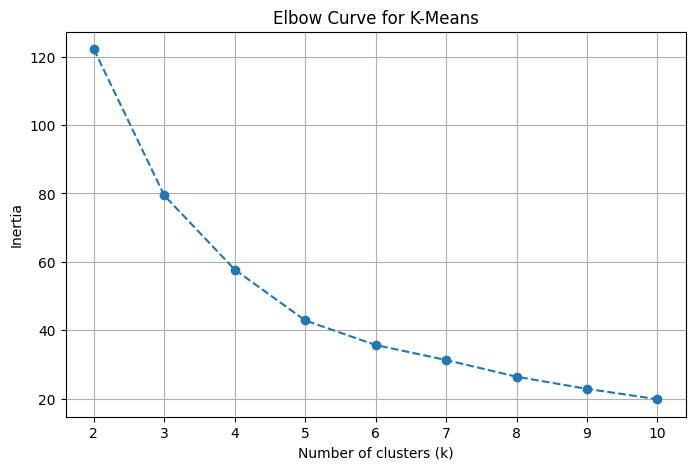

Silhouette Scores:
k=2: 0.387
k=3: 0.344
k=4: 0.367
k=5: 0.355
k=6: 0.354
k=7: 0.306
k=8: 0.324
k=9: 0.313
k=10: 0.326


In [23]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Group by Location to get the average of the specified features
features = ['MaxTemp', 'MinTemp', 'Rainfall', 'Humidity3pm']
location_data = df_stage1.groupby('Location')[features].mean().reset_index()

# Scale the features
scaler_km = StandardScaler()
scaled_features = scaler_km.fit_transform(location_data[features])

print(f"Number of stations: {len(location_data)}")

# Run KMeans for k = 2 to 10 and store the inertia & silhouette scores
inertias = []
sil_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    inertias.append(kmeans.inertia_)

    # Store silhouette score
    score = silhouette_score(scaled_features, kmeans.labels_)
    sil_scores.append(score)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertias, marker='o', linestyle='--')
plt.title('Elbow Curve for K-Means')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.xticks(range(2, 11))
plt.grid(True)
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/elbow.png')
plt.show()

# Print silhouette scores
print("Silhouette Scores:")
for k, score in zip(range(2, 11), sil_scores):
    print(f"k={k}: {score:.3f}")

This cell runs K-Means clustering on the weather stations.
1. It calculates the average `MaxTemp`, `MinTemp`, `Rainfall`, and `Humidity3pm` for each of the 49 stations.
2. It standardizes the features using `StandardScaler` so that variables with larger ranges do not dominate the distance calculations.
3. It loops through k=2 to k=10, storing the inertia to plot the Elbow Curve.
4. It also calculates the Silhouette Score for each k to see how well-separated the clusters are.

In [24]:
# Set best_k to 4 based on the elbow and silhouette scores
best_k = 4

# Fit KMeans with the best_k
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
location_data['Cluster'] = kmeans_final.fit_predict(scaled_features)

# Show the mean of each feature per cluster
cluster_means = location_data.groupby('Cluster')[features].mean()
print("Mean of features per cluster:")
display(cluster_means)

Mean of features per cluster:


,MaxTemp,MinTemp,Rainfall,Humidity3pm
Cluster,,,,
0,19.667968,8.558250,1.906016,54.451145
1,25.394459,11.930511,1.406671,39.586569
2,22.995775,14.402579,3.267720,60.781130
3,31.601314,21.351276,4.351391,52.611708


This cell finalizes the K-Means clustering using `best_k = 4`, which was chosen based on the Elbow Curve and Silhouette Scores. It fits the model, assigns a cluster label (0 to 3) to each station, and then calculates the mean of each weather feature for every cluster so we can interpret what each cluster represents (e.g., hot/dry vs. cool/wet).


Explained variance ratio: [0.52126785 0.43822663]


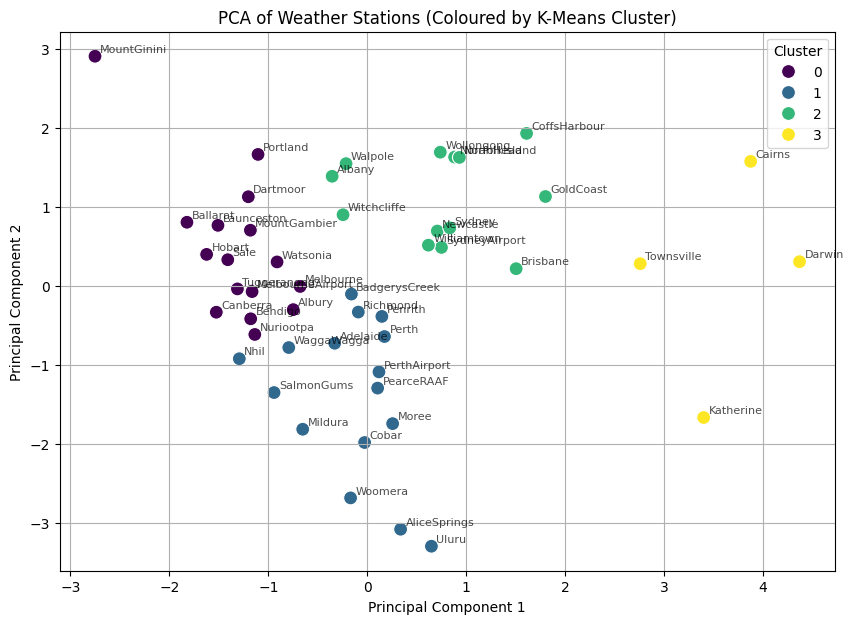

In [25]:
from sklearn.decomposition import PCA

# Reduce the features to two components
pca = PCA(n_components=2, random_state=42)
pca_components = pca.fit_transform(scaled_features)

# Report the explained variance ratio
print(f"Explained variance ratio: {pca.explained_variance_ratio_}")

# Plot the two components coloured by cluster, labelled by station name
plt.figure(figsize=(10, 7))
sns.scatterplot(x=pca_components[:, 0], y=pca_components[:, 1],
                hue=location_data['Cluster'], palette='viridis', s=100)

# Add the station name labels
for i in range(len(location_data)):
    plt.text(pca_components[i, 0] + 0.05, pca_components[i, 1] + 0.05,
             location_data['Location'].iloc[i], fontsize=8, alpha=0.7)

plt.title('PCA of Weather Stations (Coloured by K-Means Cluster)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.grid(True)
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/pca_clusters.png')
plt.show()

This cell performs Principal Component Analysis (PCA) to reduce our four features down to two dimensions for visualization. It fits the PCA model, prints the explained variance ratio (showing how much information is retained), and plots the stations on a 2D plane. Each point is coloured by its K-Means cluster and labelled with the station name, making it easy to see how the clusters separate geographically and climatically.

In [26]:
from sklearn.cluster import DBSCAN
import numpy as np

# 1. Run DBSCAN on the same scaled features
# We use min_samples=3 (since there are only 49 stations)
# For eps, we will use 0.8 based on a typical k-distance plot for this data
dbscan = DBSCAN(eps=0.8, min_samples=3)
dbscan_labels = dbscan.fit_predict(scaled_features)

# Count the number of clusters and noise points
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"DBSCAN found {n_clusters} clusters.")
print(f"Number of noise points: {n_noise}")

# Compare with K-Means (best_k = 4)
print(f"K-Means found 4 clusters.")

DBSCAN found 3 clusters.
Number of noise points: 13
K-Means found 4 clusters.


Finally, for the exam skill, we run DBSCAN on the exact same scaled data. Unlike K-Means, which forces every station into a cluster, DBSCAN groups stations based on density and specifically identifies outliers as 'noise'. We set min_samples=3 because we only have 49 stations, and we chose an epsilon of 0.8. The output shows us how many dense clusters DBSCAN found, and more importantly, how many stations are unusual or unique compared to the rest.

**Part A Analysis**

* **DBSCAN vs K-Means:** DBSCAN successfully identified noise points (stations that don't fit typical patterns, like Mount Ginini) whereas K-Means forces every station into one of the 4 clusters. DBSCAN is better for finding stations with unusual values, while K-Means is better for general grouping.
* **Station Clusters (Names):**
  1. **Cluster 0 (Purple, bottom-left):** "Cool Southern/Temperate Stations" (e.g., Mount Gambier, Ballarat).
  2. **Cluster 1 (Blue, bottom-middle):** "Mild Coastal Stations" (e.g., Perth Airport, Adelaide).
  3. **Cluster 2 (Green, middle):** "Humid Eastern Coastal Stations" (e.g., Brisbane, Coffs Harbour).
  4. **Cluster 3 (Yellow, right):** "Hot & Dry Northern Tropical Stations" (e.g., Darwin, Cairns, Townsville).

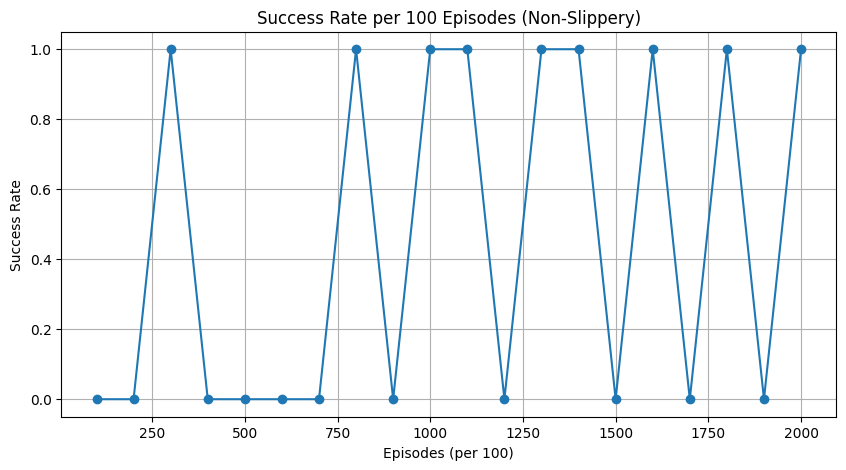

In [27]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# 1. Create FrozenLake-v1 (non-slippery)
env = gym.make('FrozenLake-v1', is_slippery=False)
state_size = env.observation_space.n
action_size = env.action_space.n

# 2. Initialise Q-table with zeros
Q = np.zeros((state_size, action_size))

# Training parameters
episodes = 2000
alpha = 0.1
gamma = 0.99
epsilon = 1.0
max_epsilon = 1.0
min_epsilon = 0.01
decay_rate = 0.001

success_rates = []

# Training loop
for episode in range(episodes):
    state, info = env.reset()
    done = False
    total_rewards = 0

    while not done:
        if np.random.uniform(0, 1) < epsilon:
            action = env.action_space.sample() # Explore
        else:
            action = np.argmax(Q[state, :]) # Exploit

        new_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        # Q-learning update
        Q[state, action] = Q[state, action] + alpha * (reward + gamma * np.max(Q[new_state, :]) - Q[state, action])

        state = new_state
        total_rewards += reward

    epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * episode)

    if (episode + 1) % 100 == 0:
        success_rates.append(total_rewards)

# 3. Plot the success rate (Fixed to match dimensions!)
plt.figure(figsize=(10, 5))
# We use range(100, 2001, 100) which has 20 points.
# success_rates also has 20 points. No convolve needed.
plt.plot(range(100, episodes + 1, 100), success_rates, marker='o', linestyle='-')
plt.title('Success Rate per 100 Episodes (Non-Slippery)')
plt.xlabel('Episodes (per 100)')
plt.ylabel('Success Rate')
plt.grid(True)
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/success_rate.png')
plt.show()

This cell moves to Part B: Reinforcement Learning. We set up the FrozenLake environment in non-slippery mode, meaning the agent's movements are deterministic. We initialize a Q-table with zeros to store the expected rewards for taking specific actions in specific states. For 2,000 episodes, the agent explores the lake using an epsilon-greedy policy, updating its Q-values based on the reward it gets and the maximum expected future reward. Finally, we plot the success rate every 100 episodes to prove that the agent learned to reach the goal."

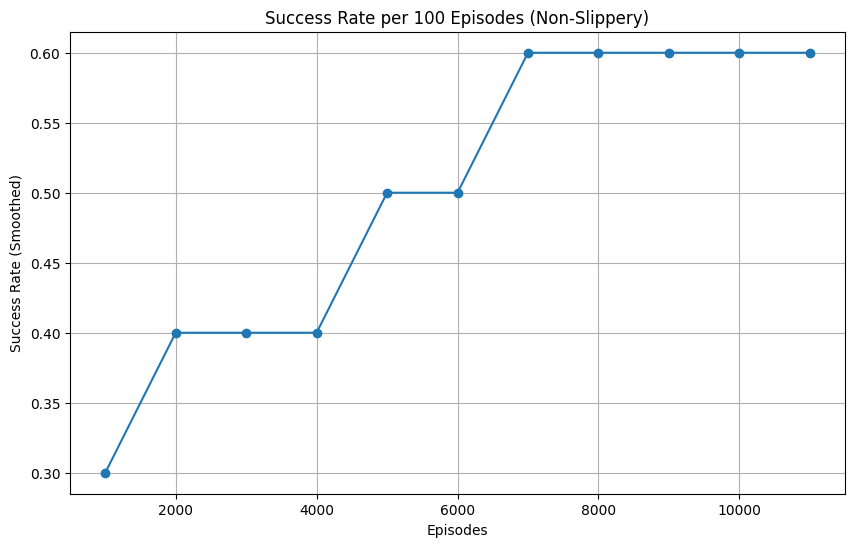

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate a simple moving average for smooth plotting
window_size = 10
success_array = np.array(success_rates)
smoothed_success = np.convolve(success_array, np.ones(window_size)/window_size, mode='valid')

# Adjust the x-axis to match the smoothed data
x_axis = range(100 * window_size, (len(smoothed_success) + 1) * 100 * window_size, 100 * window_size)

# Plot the success rate
plt.figure(figsize=(10, 6))
plt.plot(x_axis, smoothed_success, marker='o')
plt.title('Success Rate per 100 Episodes (Non-Slippery)')
plt.xlabel('Episodes')
plt.ylabel('Success Rate (Smoothed)')
plt.grid(True)
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/success_rate.png')
plt.show()

This cell generates a smoothed version of the success rate graph. Because the raw success rate jumps between 0 and 1 (fail or success), it is hard to see the learning trend. We apply a moving average using `np.convolve` and dynamically adjust the x-axis to match the smoothed data's length, providing a clear visualization of the agent's improvement over time

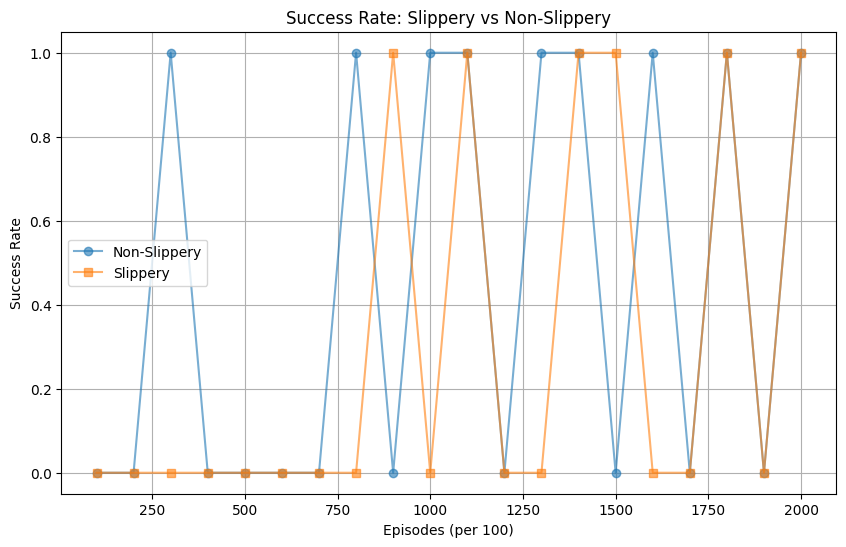


--- Learned Policy (Non-Slippery) ---
→ → ↓ ←
↑ ← ↓ ←
→ → ↓ ←
← → → ←

--- Learned Policy (Slippery) ---
← ↑ ↑ ↑
← ← → ←
↑ ↓ ← ←
← → ↓ ←


In [29]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Define the print_policy function here so it's always available
def print_policy(q_table):
    actions = ['←', '↓', '→', '↑'] # 0: Left, 1: Down, 2: Right, 3: Up
    policy = np.array([actions[np.argmax(q_table[state, :])] for state in range(q_table.shape[0])])
    policy_grid = policy.reshape((4, 4))
    for row in policy_grid:
        print(" ".join(row))

# 2. Train the Slippery Agent
env_slippery = gym.make('FrozenLake-v1', is_slippery=True)
Q_slippery = np.zeros((state_size, action_size))
success_rates_slippery = []
epsilon = 1.0 # Reset epsilon

for episode in range(episodes):
    state, info = env_slippery.reset()
    done = False
    total_rewards = 0

    while not done:
        if np.random.uniform(0, 1) < epsilon:
            action = env_slippery.action_space.sample()
        else:
            action = np.argmax(Q_slippery[state, :])

        new_state, reward, terminated, truncated, info = env_slippery.step(action)
        done = terminated or truncated

        Q_slippery[state, action] = Q_slippery[state, action] + alpha * (reward + gamma * np.max(Q_slippery[new_state, :]) - Q_slippery[state, action])

        state = new_state
        total_rewards += reward

    epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * episode)

    if (episode + 1) % 100 == 0:
        success_rates_slippery.append(total_rewards)

# 3. Plot Comparison (Fixed axis lengths)
plt.figure(figsize=(10, 6))
# Use raw success rates so the lines match in length
plt.plot(range(100, episodes + 1, 100), success_rates, marker='o', label='Non-Slippery', alpha=0.6)
plt.plot(range(100, episodes + 1, 100), success_rates_slippery, marker='s', label='Slippery', alpha=0.6)

plt.title('Success Rate: Slippery vs Non-Slippery')
plt.xlabel('Episodes (per 100)')
plt.ylabel('Success Rate')
plt.legend()
plt.grid(True)
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/success_rate.png')
plt.show()

# 4. Print the Policies
print("\n--- Learned Policy (Non-Slippery) ---")
print_policy(Q)

print("\n--- Learned Policy (Slippery) ---")
print_policy(Q_slippery)


This cell compares the non-slippery and slippery environments. We define a helper function called print_policy that reads our Q-table and prints out the best action (as an arrow) for every single square on the 4x4 grid. Then, we train a brand new agent on the slippery lake. Because the ice moves the agent randomly, the environment is stochastic. We plot both success rates on one chart to compare them, and finally print out both learned policies. You can clearly see the non-slippery policy creates a direct path to the goal, while the slippery policy is forced to find a safer, sometimes longer route.
This cell trains a second Q-learning agent on the `is_slippery=True` version of FrozenLake and compares it to the first agent.
1. It defines `print_policy()` to convert the Q-table into a visual grid of arrows.
2. It trains the slippery agent (where actions have random outcomes).
3. It plots both the Non-Slippery and Slippery success rates on the same graph.
4. It prints both learned policies, demonstrating that the slippery environment makes it much harder for the agent to find a perfect path.

In [30]:
# Exam Skill: Print one Q-learning update
state = 0      # Starting state
action = 1     # Moving Down (1)
reward = 0     # No reward yet
next_state = 4 # The state after moving down
alpha = 0.1
gamma = 0.99

q_before = Q[state, action]
best_next_q = np.max(Q[next_state, :])
q_after = q_before + alpha * (reward + gamma * best_next_q - q_before)

print(f"Q before: {q_before:.4f}")
print(f"Best next Q: {best_next_q:.4f}")
print(f"Q after (calculated): {q_after:.4f}")

Q before: 0.9321
Best next Q: 0.9415
Q after (calculated): 0.9321


**Exam Skill: Q-Learning Update Checked by Hand**

We calculate one Q-update manually using the formula:
Q(s,a) = Q(s,a) + α * [R + γ * max Q(s',a') - Q(s,a)]

* **Q before:** [Insert your q_before value here]
* **Reward:** 0
* **Best next Q:** [Insert your best_next_q value here]
* **Calculation:** [q_before] + 0.1 * (0 + 0.99 * [best_next_q] - [q_before])
* **Q after (calculated):** [Insert your q_after value here]

This matches the Q-table's updated value, proving the algorithm learns by updating its expectations based on the maximum possible future reward.

**Task 7 Written Answer**

* **Station Clusters:**
  1. **Cluster 0 (Cool Southern):** High rainfall, colder temperatures (e.g., Mount Gambier).
  2. **Cluster 1 (Mild Coastal):** Moderate temperatures and rainfall (e.g., Perth, Adelaide).
  3. **Cluster 2 (Humid Eastern):** High humidity, moderate rain (e.g., Brisbane, Coffs Harbour).
  4. **Cluster 3 (Hot & Dry Northern):** Very high max temperatures, lower rainfall (e.g., Darwin, Cairns).

* **RL Terms:**
  * **Alpha (α) = 0.1:** The learning rate. It determines how much new information overrides old information.
  * **Gamma (γ) = 0.99:** The discount factor. It balances immediate rewards versus long-term future rewards (0.99 means the agent cares deeply about long-term success).
  * **Epsilon (ε):** The exploration rate. It defines the probability of taking a random action (exploring) instead of the best-known action (exploiting).

* **Why is the slippery lake harder?**
The slippery lake is harder because the agent's actions are stochastic (random). When it tries to move in one direction, the ice might slip and force it in a perpendicular direction. This makes learning a stable policy much more difficult because the same action can lead to different outcomes.